# Wine data: use Codex, then review its code

**The process:** give a prompt → copy the commented code → read and ask questions → run and check.

We use real Wine chemical measurements from scikit-learn. We want a summary and figures comparing three cultivar groups.
There is no planted mistake to find. Your job is to understand what the generated code does before accepting it.

Open this folder in Codex. Keep Jupyter beside it so you can review and run small blocks.
If imports fail, run `%pip install numpy matplotlib scikit-learn`, then restart the kernel.

## 1. Give Codex the task

Copy this prompt:

> Use sklearn.datasets.load_wine to analyze the Wine chemical measurements.
> For each measurement, calculate count, mean, minimum, and maximum within each cultivar group.
> Make a separate comparison figure for each measurement, showing individual samples and group means.
> Save the summary as CSV and the figures as PNG. Use NumPy, Matplotlib, and csv; no machine learning.
> Split the code into small notebook cells. Add simple comments explaining the logic, especially how the correct samples are selected.
> Show me the code first so I can review it before running it.

## 2. Copy the code and read the comments

Copy your actual Codex response into notebook cells. The five cells below are a **commented reference example** you can use
for a rehearsal; they are not a recorded Codex response.

Before each block, read its comments and follow the corresponding lines. If a line is unclear, ask Codex before running it.

In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

# Load the real measurements and the supplied cultivar labels.
wine = load_wine()
features = list(wine.feature_names)
print("Samples and measurements:", wine.data.shape)

Samples and measurements: (178, 13)


**Review the grouping logic:** each row is a wine sample; each column is a measurement.
`wine.target` gives the supplied cultivar label for each row: 0, 1, or 2.
In the report, we display these as Cultivar 1, 2, and 3.

In the next block, check that the group filter and feature column select the values you want.

In [2]:
summary = []
# Repeat the same calculation for every feature and each cultivar.
for column, feature in enumerate(features):
    for group in range(3):
        # Keep this feature's values only for wines in the chosen group.
        values = wine.data[wine.target == group, column]
        summary.append({
            "feature": feature, "cultivar": group + 1, "count": len(values),
            "mean": float(np.mean(values)), "minimum": float(np.min(values)),
            "maximum": float(np.max(values)),
        })
# Show only alcohol as a small example to review.
for row in summary[:3]:
    print(row)

{'feature': 'alcohol', 'cultivar': 1, 'count': 59, 'mean': 13.744745762711865, 'minimum': 12.85, 'maximum': 14.83}
{'feature': 'alcohol', 'cultivar': 2, 'count': 71, 'mean': 12.278732394366195, 'minimum': 11.03, 'maximum': 13.86}
{'feature': 'alcohol', 'cultivar': 3, 'count': 48, 'mean': 13.153750000000002, 'minimum': 12.2, 'maximum': 14.34}


## 3. Ask when a line is unclear

For example, copy this question to Codex:

> Explain `wine.data[wine.target == group, column]` in plain language.
> Which samples are included? How does column choose the measurement?
> Show me the alcohol / Cultivar 1 example. Explain it without changing the code yet.

Then say the rule in your own words: **calculate each statistic using one measurement from only the wines in that cultivar**.
Comments help explain the intended logic; check that the code actually follows it.

## 4. Run a small check

Run only the blocks you have reviewed. Inspect the source dimensions and group counts.
For one result, calculate the alcohol mean a second way using ordinary Python `sum / count`.

In [3]:
# Check the dataset size, group sizes, and number of summary rows.
assert wine.data.shape == (178, 13)
print("Cultivar counts:", np.bincount(wine.target).tolist())
assert np.bincount(wine.target).tolist() == [59, 71, 48]
assert len(summary) == 13 * 3

# Check one mean directly from the original measurements.
column = features.index("alcohol")
source_values = [float(wine.data[i, column]) for i in range(178) if wine.target[i] == 0]
manual_mean = sum(source_values) / len(source_values)
assert np.isclose(summary[0]["mean"], manual_mean)
print("Alcohol / Cultivar 1 mean agrees:", round(manual_mean, 4))

Cultivar counts: [59, 71, 48]
Alcohol / Cultivar 1 mean agrees: 13.7447


**Review the plot code:** it should select the same group values, plot the original measurements,
and mark the arithmetic mean. The function makes one figure so it can be reused.
Preview alcohol and compare the black mean markers with the table above.

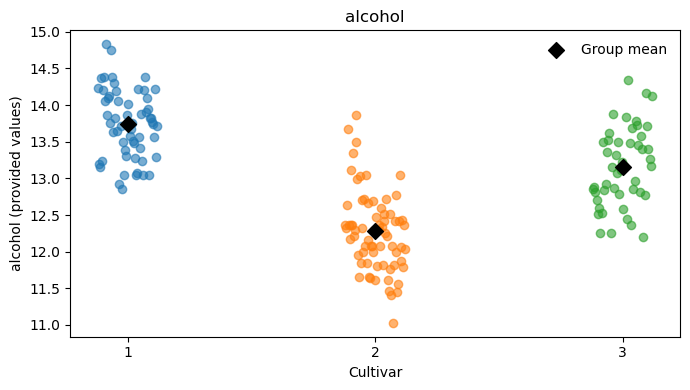

In [4]:
def plot_measurement(column):
    fig, ax = plt.subplots(figsize=(7, 4))
    for group in range(3):
        values = wine.data[wine.target == group, column]
        # Horizontal spacing separates points; y-values remain unchanged.
        x = group + 1 + np.linspace(-0.12, 0.12, len(values))
        ax.scatter(x, values, alpha=0.6)
        ax.scatter(group + 1, np.mean(values), color="black", marker="D", s=65,
                   label="Group mean" if group == 0 else None)
    ax.set_xticks([1, 2, 3])
    ax.set_xlabel("Cultivar")
    ax.set_ylabel(features[column] + " (provided values)")
    ax.set_title(features[column].replace("_", " "))
    ax.legend(frameon=False)
    fig.tight_layout()
    return fig

fig = plot_measurement(features.index("alcohol"))
plt.show()
plt.close(fig)

## 5. Continue once you understand the logic

Review where files will be saved. Then run the final block to repeat the same plotting logic across the measurements.
It writes only generated reports to `wine_report`.

If you want a change, describe it to Codex, review the revised code, and rerun the relevant check.
For example: **“Put the three cultivar counts in the plot labels. Explain which lines you changed.”**

In [5]:
output = Path("wine_report")
output.mkdir(exist_ok=True)
# Save the group summary as a CSV table.
with (output / "group_summary.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(summary[0]))
    writer.writeheader()
    writer.writerows(summary)

# Reuse the reviewed plotting function for all measurements.
for column, feature in enumerate(features):
    fig = plot_measurement(column)
    fig.savefig(output / (feature.replace("/", "_") + ".png"), dpi=150)
    plt.close(fig)
print("Saved the summary and 13 figures in wine_report/.")

Saved the summary and 13 figures in wine_report/.


**What to practice:** ask Codex about one line you do not understand, explain that line in your own words,
and identify how you checked it.

**Source:** [Wine, UCI](https://archive.ics.uci.edu/dataset/109/wine), Aeberhard & Forina (1992),
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), loaded with
[scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html).
Cultivar labels are supplied with the data. Units are not invented; groups are not replicate measurements.